# **Set Up PACE and Granules**

In [3]:
import earthaccess

earthaccess.login(strategy="interactive", persist=True)
print("Logged in to NASA Earthdata.")

Logged in to NASA Earthdata.


### Load and parse the CAML SeaBASS (`.sb`) file

In [4]:
from pathlib import Path

# CAML SeaBASS file is inside the cyfi folder
SB_PATH = Path("cyfi") / "0c233b5a95_CAML_cyanobacteria_abundance_20211229_R1.sb"

assert SB_PATH.exists(), f"Couldn't find {SB_PATH}"

print(f"Using SeaBASS file: {SB_PATH}")

Using SeaBASS file: cyfi\0c233b5a95_CAML_cyanobacteria_abundance_20211229_R1.sb


In [5]:
import pandas as pd

# Reads a NASA SeaBASS file: "/key=value" header lines, then the data table.
# Returns (data table, header dictionary).
def load_seabass(path):
    header = {}

    # Read every line of the file into a list
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        lines = f.readlines()

    end_idx = None # line number of "/end_header" (the data starts after it)

    for i, line in enumerate(lines): 
        stripped = line.strip() # remove spaces and the newline at each end

        if stripped == "/end_header": # header is over: remember where and stop
            end_idx = i
            break

        if stripped.startswith("/") and "=" in stripped:  # a "/key=value" header line
            key, _, val = stripped[1:].partition("=") # drop the "/" and split at the first "="
            header[key] = val # store it

    if end_idx is None:
        raise ValueError(
            f"No '/end_header' found in {path} -- is this a valid .sb file?"
        )

    # Determine delimiter
    delimiter_map = {
        "comma": ",",
        "space": r"\s+",
        "tab": "\t"
    }

    delimiter = delimiter_map.get(
        header.get("delimiter", "comma"),
        ","
    )

    # Column names come from the header's "fields" line, e.g. "date,time,lat,lon,..."
    fields = header["fields"].split(",")

    # Get missing-value indicator
    missing_value = float(header.get("missing", -9999))

    # Read data after the SeaBASS header
    data = pd.read_csv(
        path,
        skiprows=end_idx + 1, # skip all the header lines
        header=None, # the data has no column-name row...
        names=fields,
        delimiter=delimiter, # column separator found above
        na_values=[missing_value], # turn -9999 into NaN (missing)
        engine="python",
        encoding="utf-8",
        encoding_errors="replace",
    )

    print(f"Loaded {len(data):,} rows, {len(fields)} fields from {path}")
    print(f"Date range: {header.get('start_date')} to {header.get('end_date')}")
    print(f"Investigators: {header.get('investigators', 'n/a')}")

    return data, header


# Load CAML data
caml_raw, sb_header = load_seabass(SB_PATH)

# Display first rows
caml_raw.head()

Loaded 23,570 rows, 10 fields from cyfi\0c233b5a95_CAML_cyanobacteria_abundance_20211229_R1.sb
Date range: 20130104 to 20211229
Investigators: Shobhana_Gupta,Emily_Gelbart,Ritwik_Gupta,Katie_Wetstone,Emily_Dorne


,uid,data_provider,region,lat,lon,date,time,abun,severity,distance_to_water_m
0,aabm,Indiana_State_Department_of_Health,midwest,39.080319,-86.430867,20180514,15:00:00,0.585,1,0.0
1,aabn,California_Environmental_Data_Exchange_Network,west,36.559700,-121.510000,20160831,16:15:00,5867.500,4,3512.0
2,aacd,NC_Division_of_Water_Resources_NC_Department_o...,south,35.875083,-78.878434,20201119,0:01:00,0.290,1,514.0
3,aaee,NC_Division_of_Water_Resources_NC_Department_o...,south,35.487000,-79.062133,20160824,0:01:00,1.614,1,129.0
4,aaff,Bureau_of_Water_Kansas_Department_of_Health_an...,midwest,38.049471,-99.827001,20190723,0:01:00,111.825,3,19.0


### Convert to CyFi's expected training format

In [6]:
import numpy as np

# Converts CAML's columns into the format CyFi expects
def caml_to_cyfi_labels(df):
    out = pd.DataFrame({
        "date": pd.to_datetime(df["date"], format="%Y%m%d"),
        "latitude": df["lat"],
        "longitude": df["lon"],
        "density_cells_per_ml": df["abun"] * 1000,   # abun is 10^3 cells/mL
        "region": df["region"],
        "severity": df["severity"],
        "distance_to_water_m": df["distance_to_water_m"],
    }).dropna(subset=["latitude", "longitude", "date", "density_cells_per_ml"])

    # reconstructed severity must match CAML's
    bins = [0, 2e4, 1e5, 1e6, 1e7, np.inf]
    recon = pd.cut(out["density_cells_per_ml"], bins=bins, labels=[1,2,3,4,5],
                   right=False).astype(int)
    agree = (recon == out["severity"]).mean()
    assert agree > 0.99, f"units are wrong: only {agree:.1%} of severities match"

    return out

cyfi_labels = caml_to_cyfi_labels(caml_raw)

In [7]:
usable = cyfi_labels[ # Keep only samples a satellite could have seen
    (cyfi_labels["date"] >= "2016-01-01") & # Sentinel-2 imagery starts in 2015
    (cyfi_labels["distance_to_water_m"] <= 1000) # within 1 km of mapped water
].copy()
usable["date"] = usable["date"].dt.strftime("%Y-%m-%d")
usable = usable.drop_duplicates(subset=["date", "latitude", "longitude"])
print(f"{len(usable):,} of {len(cyfi_labels):,} usable")

15,169 of 23,570 usable


### Look at the labels

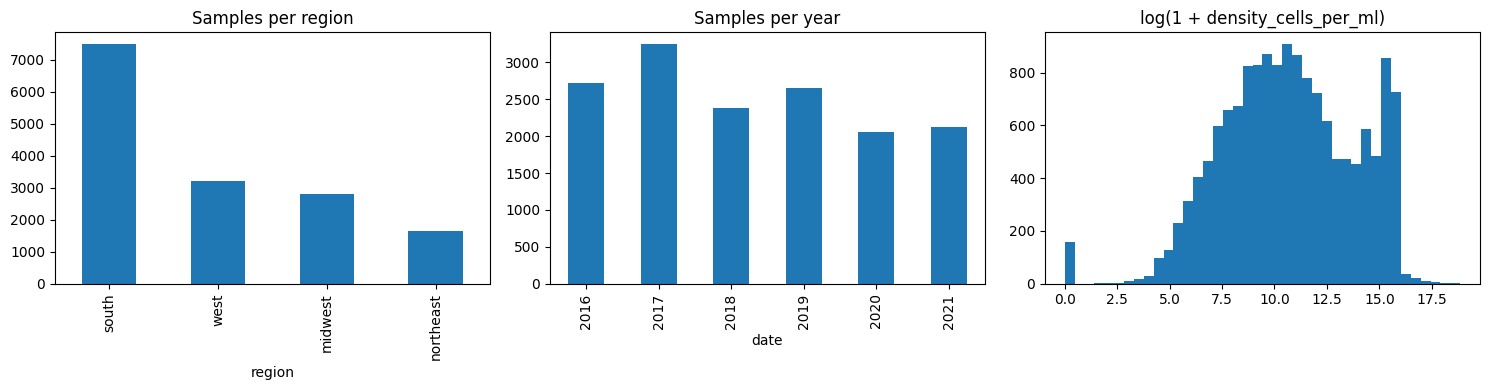

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: number of samples in each region
usable["region"].value_counts().plot(kind="bar", ax=axes[0], title="Samples per region")

# Plot 2: number of samples in each year (in year order)
pd.to_datetime(usable["date"]).dt.year.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="Samples per year"
)

# Plot 3: spread of densities on a log scale (they range from 0 to millions)
axes[2].hist(np.log1p(usable["density_cells_per_ml"]), bins=40)
axes[2].set_title("log(1 + density_cells_per_ml)")

plt.tight_layout()
plt.show()

### Train / test split

In [9]:
from sklearn.model_selection import train_test_split
import shutil

N_SAMPLES = None # how many samples to use; None = all
RANDOM_STATE = 40 # fixed seed

labels_for_run = usable.copy()

if N_SAMPLES is not None and len(labels_for_run) > N_SAMPLES:
    labels_for_run, _ = train_test_split(
        labels_for_run,
        train_size=N_SAMPLES,
        stratify=labels_for_run["region"],
        random_state=RANDOM_STATE,
    )

train_labels, test_labels = train_test_split(
    labels_for_run,
    test_size=0.2,
    stratify=labels_for_run["region"],
    random_state=RANDOM_STATE,
)

# CyFi only wants these four columns; severity and distance_to_water_m
# were only for filtering and the units assert
CYFI_COLS = ["date", "latitude", "longitude", "density_cells_per_ml"]
train_labels[CYFI_COLS].to_csv("caml_train.csv", index=False)
test_labels[CYFI_COLS].to_csv("caml_test.csv", index=False)

shutil.rmtree("chunks", ignore_errors=True)   # stale preds no longer match caml_test.csv

print(f"Train: {len(train_labels):,}   Test: {len(test_labels):,}")

Train: 12,135   Test: 3,034


### Evaluate CyFi's pretrained model

In [11]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd

CYFI_PATH = Path("cyfi") # folder holding the CyFi code
sys.path.insert(0, str(CYFI_PATH)) # let Python import "cyfi" from that folder

from cyfi.pipeline import CyFiPipeline # CyFi's main class (features + model)
from cyfi.config import FeaturesConfig, CyFiModelConfig # CyFi's settings classes

DEFAULT_MODEL_PATH = CYFI_PATH / "cyfi" / "assets" / "model_v0.zip" # The pretrained model that comes with CyFi
assert DEFAULT_MODEL_PATH.exists(), f"Could not find pretrained model: {DEFAULT_MODEL_PATH}"

print(f"Using CyFi repository: {CYFI_PATH.resolve()}")
print(f"Using pretrained model: {DEFAULT_MODEL_PATH.resolve()}")

# load the pretrained model; downloaded imagery is cached in cyfi_cache/
baseline_pipeline = CyFiPipeline.from_disk(str(DEFAULT_MODEL_PATH), cache_dir="cyfi_cache")

# ---- predict the test set in chunks, retrying on network errors ----
test_df = pd.read_csv("caml_test.csv") # the test samples
CHUNK = 250 # samples per chunk
chunk_dir = Path("chunks"); chunk_dir.mkdir(exist_ok=True) # folder for finished chunks
parts = []

for i in range(0, len(test_df), CHUNK):
    tag = i // CHUNK
    in_csv  = chunk_dir / f"test_{tag}.csv"
    out_csv = chunk_dir / f"preds_{tag}.csv"

    if out_csv.exists():
        parts.append(pd.read_csv(out_csv)); continue

    test_df.iloc[i:i+CHUNK].to_csv(in_csv, index=False)

    for attempt in range(5):
        try:
            # CyFi downloads imagery, builds features and predicts, saving to out_csv
            baseline_pipeline.run_prediction(str(in_csv), preds_path=str(out_csv))
            break
        except Exception as e:
            wait = 30 * (2 ** attempt)
            print(f"chunk {tag} attempt {attempt+1} failed ({type(e).__name__}); sleeping {wait}s")
            time.sleep(wait)
    else:
        print(f"chunk {tag} gave up"); continue

    parts.append(pd.read_csv(out_csv))
    time.sleep(5)

preds = pd.concat(parts)
preds.to_csv("preds_pretrained.csv", index=False)
print(f"{len(preds):,} predictions written")
preds.head()

Using CyFi repository: C:\Users\skidd\GCLWorkspace\cyfi
Using pretrained model: C:\Users\skidd\GCLWorkspace\cyfi\cyfi\assets\model_v0.zip


2026-10-15 01:52:25.491 | SUCCESS  | cyfi.pipeline:_prep_predict_data:287 - Loaded 250 sample points (unique combinations of date, latitude, and longitude) for prediction
2026-10-15 01:52:25.499 | INFO     | cyfi.data.satellite_data:generate_candidate_metadata:251 - Searching Sentinel-2 for satellite imagery for 250 sample points.


  0%|          | 0/250 [00:00<?, ?it/s]

2026-10-15 01:55:35.605 | INFO     | cyfi.data.satellite_data:identify_satellite_data:349 - Searched Sentinel-2 with buffers of 30 days and 2,000 meters. Identified satellite imagery to generate features for 250 sample points (100%)
2026-10-15 01:55:36.379 | INFO     | cyfi.pipeline:_prepare_features:113 - Satellite imagery metadata saved to cyfi_cache\a704f3a4653d651a8a156bbc3e783fce\satellite_metadata_test.csv
2026-10-15 01:55:36.382 | PROGRESS | cyfi.data.satellite_data:download_satellite_data:456 - Downloading satellite imagery for 1,640 Sentinel-2 items.


  0%|          | 0/1640 [00:00<?, ?it/s]

...

2026-10-15 03:43:06.183 | INFO     | cyfi.data.features:calculate_satellite_features:64 - Dropping 143 row(s) where bounding box has too many clouds.
2026-10-15 03:43:06.186 | INFO     | cyfi.data.features:calculate_satellite_features:73 - Dropping 22 row(s) where bouding box does not contain any water.
2026-10-15 03:43:06.190 | INFO     | cyfi.data.features:calculate_satellite_features:79 - Dropping 1 row(s) where bouding box contains missing pixels.
2026-10-15 03:43:06.231 | WARNING  | cyfi.data.features:generate_all_features:294 - Relevant satellite data is not available for all sample points. Features will only be generated for 26 sample points with valid satellite imagery (76% of sample points)
2026-10-15 03:43:06.391 | INFO     | cyfi.data.features:calculate_metadata_features:219 - Generating land cover features for 34 sample points.


  0%|          | 0/34 [00:00<?, ?it/s]

2026-10-15 03:43:12.089 | INFO     | cyfi.data.features:generate_all_features:317 - Generated 29 satellite feature(s) and 1 sample metadata feature(s) for 26 sample points (76% of sample points)
2026-10-15 03:43:12.128 | SUCCESS  | cyfi.pipeline:_write_predictions:335 - Cyanobacteria estimates for 26 sample points saved to chunks\preds_12.csv


3,034 predictions written


,sample_id,date,latitude,longitude,density_cells_per_ml,severity
0,18eaedb11bdc8759ea57fb828f7b988b,2017-07-13,35.980000,-78.777021,27990.0,moderate
1,32282e123d17044dca0ab2384fa7918c,2019-08-20,41.443090,-75.194800,97864.0,moderate
2,b28912f959084307efea102c29f5885c,2021-07-21,35.430000,-79.086108,14517.0,low
3,11b53a65f1647449926acb08607dae03,2018-08-12,42.281667,-81.671667,3396.0,low
4,a9d458b7cdb135c1a6c148af5dcd40fa,2016-10-05,35.713374,-79.149878,NaN,NaN


2026-10-15 11:20:02.496 | INFO     | cyfi.evaluate:__init__:166 - Evaluating on 2,145 sample points (of 3,034)


Overall severity RMSE: 0.686
Overall log-density R²: 0.584
Missing predictions: 29.3%


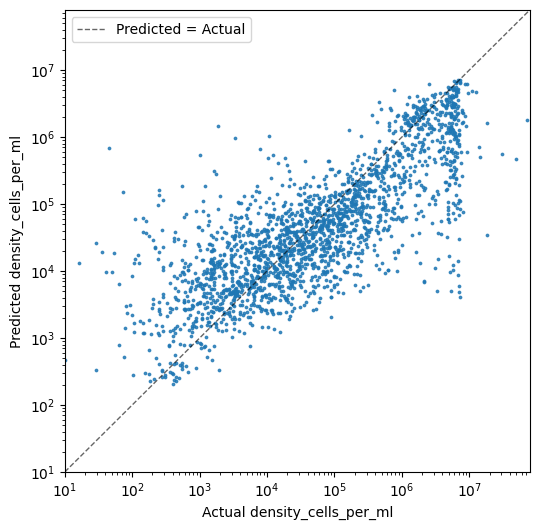

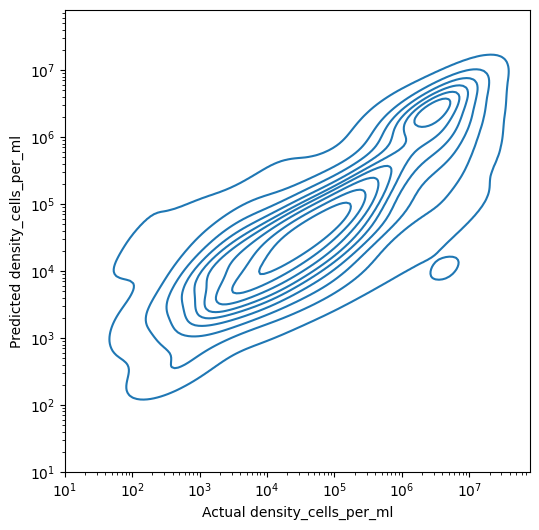

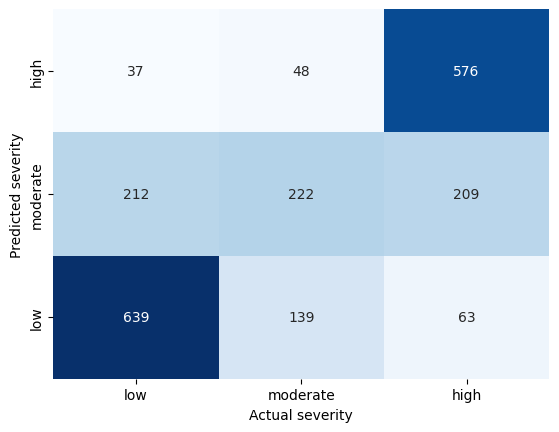

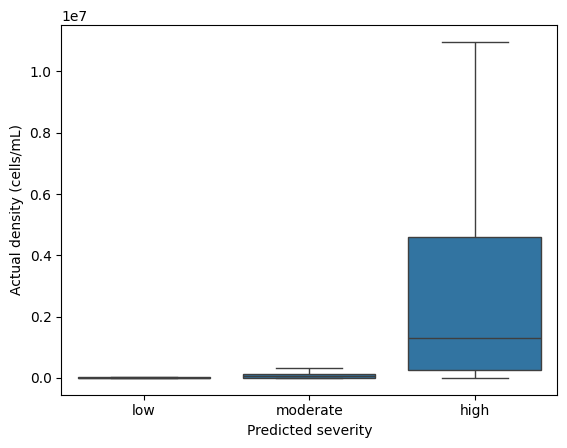

In [1]:
from cyfi.evaluate import EvaluatePreds  # CyFi's scoring and plotting tool
import json

# Compare CyFi's predictions with the real measurements in the test set
pretrained_eval = EvaluatePreds(
    y_pred_csv="preds_pretrained.csv", # the predictions
    y_true_csv="caml_test.csv", # the real measurements
    save_dir="metrics_pretrained", # written to this
)
pretrained_eval.calculate_all_and_save()

with open("metrics_pretrained/results.json") as f:
    pretrained_results = json.load(f) # Load the saved results.json file back into memory as a dict

# RMSE: typical error in severity levels (lower is better)
# R² on log density: share of variation explained (closer to 1 is better)
# Share of test samples with no prediction (no usable image)
print(f"Overall severity RMSE: {pretrained_results['severity']['overall_rmse']:.3f}")
print(f"Overall log-density R²: {pretrained_results['log_density']['overall_r_squared']:.3f}")
print(f"Missing predictions: {pretrained_results['samples_missing_predictions']['percent']:.1%}")

# **Forecasting blooms from satellite data alone (Sentinel-2 + PACE)**

This part forecasts a satellite bloom index `LEAD_DAYS` days ahead using only satellite data:

Every clear PACE view of every point becomes a training example, so there are far more examples than field sampling provides, and it works on any lake large enough for PACE's ~1 km pixels. The trade-off is that it forecasts what the satellite sees, not measured concentrations.

Steps:
1. Choose the lakes, points, seasons and lead time.
2. Get one PACE observation per point per clear day (these supply both the answers and the PACE inputs).
3. Get the latest Sentinel-2 observation for every point every few days (via CyFi).
4. Pair each forecast day with the most recent observations from at least `LEAD_DAYS` earlier.
5. Compare models against simple baselines, including "same as the last PACE view".
6. Check how well it transfers to a lake it didn't train on, then save the model.

In [22]:
# ------------------------------------------------------------------
# Forecast settings: what to predict, how far ahead, where and when
# ------------------------------------------------------------------
from cyfi.data.utils import add_unique_identifier

# Bloom index to forecast, computed from PACE's spectrum by pace_features.py.
# "pace_ci" = Cyanobacteria Index (higher = more algae). 
TARGET_INDEX = "pace_ci"

# Inputs must be at least this many days older than the forecast day
LEAD_DAYS = 7

# How far back from that cutoff to look for the most recent clear image
PACE_LOOKBACK_DAYS = 7     # PACE passes over roughly daily
S2_LOOKBACK_DAYS = 30      # Sentinel-2 passes less often; this matches CyFi's usual window

# Bloom seasons = the days being forecast, as (start, end)
SEASONS = [
    ("2025-06-01", "2025-10-31"),
    ("2024-06-01", "2024-10-31"),
    ("2026-06-01", "2026-09-28"),
]

# Points to forecast: lake name -> list of (latitude, longitude).
# Each should be open water ~2 km+ from shore (PACE pixels are ~1 km across).
# The Lake Erie points are NOAA GLERL's sampling stations
LAKES = {
    "Lake Erie": [(41.7628, -83.3294), (41.8268, -83.1929), (41.7070, -83.3837), (41.8344, -83.3584),
                  (41.7179, -83.4232), (41.7039, -83.2552), (41.7434, -83.1371), (41.6604, -83.1435)],
    "Saginaw Bay": [(43.78, -83.68)],
    "Green Bay": [(44.66, -87.88)],
    "Lake Winnebago": [(44.00, -88.42)],
    "Lake Okeechobee": [(26.95, -80.83)],
    "Utah Lake": [(40.22, -111.80)],
}

# How often (in days) to ask CyFi for the latest Sentinel-2 image at each point.
# Smaller catches more images but takes longer.
S2_QUERY_EVERY_DAYS = 5

# One row per point, e.g. "Lake Erie #3"
points = pd.DataFrame(
    [{"lake": lake, "point_id": f"{lake} #{i + 1}", "latitude": lat, "longitude": lon}
     for lake, coords in LAKES.items() for i, (lat, lon) in enumerate(coords)]
)

# Every forecast day across all seasons: each season's days, merged and sorted
target_days = pd.DatetimeIndex(sorted(set().union(*[pd.date_range(s, e) for s, e in SEASONS])))


def point_day_grid(days):
    # Every combination of point and day, indexed by CyFi's sample_id (a hash of
    # lat, lon and date), which is how both satellites' results are matched up
    grid = points.merge(pd.DataFrame({"date": days.strftime("%Y-%m-%d")}), how="cross")
    return add_unique_identifier(grid)


print(f"{len(points)} points in {points['lake'].nunique()} lakes; "
      f"{len(target_days)} days to forecast, {LEAD_DAYS} days ahead")

13 points in 6 lakes; 426 days to forecast, 7 days ahead


### PACE: one observation per point per clear day

`generate_pace_features` (from `pace_features.py`) is run with a 0-day window, so each point/day gets PACE's view from that day only, or nothing if it was cloudy. This one table supplies both the answers (the bloom index on the forecast day) and the PACE inpus). It starts a few weeks before the first forecast day so early forecasts have inputs too.

In [23]:
# ------------------------------------------------------------------
# PACE: one observation per point per clear day
# ------------------------------------------------------------------
from pace_features import PaceConfig, generate_pace_features

# Days needed: from (lead + lookback + 14) days before each season starts, to its end,
# so early forecasts have inputs and the 14-day average has history
pace_days = pd.DatetimeIndex(sorted(set().union(*[
    pd.date_range(pd.Timestamp(s) - pd.Timedelta(days=LEAD_DAYS + PACE_LOOKBACK_DAYS + 14), e)
    for s, e in SEASONS
])))
pace_grid = point_day_grid(pace_days)

# days_search_window=0: only use images from the day itself. Which day's view feeds
# which forecast is decided later, in the forecast-table cell.
pace_config = PaceConfig(
    days_search_window=0,
    min_lead_days=0,
    radius_m=2000,        # use PACE pixels within 2 km of each point
    min_valid_pixels=2,   # need at least 2 clear water pixels to count as a view
)

# Search, stream and extract PACE data (cached per day in pace_cache/, so reruns resume).
# pace_obs = features per clear point/day; pace_spectra = their spectra; pace_qc = every attempt
pace_obs, pace_spectra, pace_qc = generate_pace_features(
    pace_grid[["date", "latitude", "longitude"]], pace_config, cache_dir="pace_cache"
)

pace_obs = pace_obs.join(pace_grid[["point_id", "lake", "date"]]) # add point, lake and date (matched by sample_id)
pace_obs["date"] = pd.to_datetime(pace_obs["date"]) # text -> real dates
pace_obs = pace_obs.drop(columns=["pace_days_before_sample"])   # always 0 with a 0-day window

# Check: clear views per point (0 = probably too close to shore or on land)
clear_views = pace_obs.groupby("point_id").size().reindex(points["point_id"], fill_value=0) # count per point; 0 if never seen
print(f"{len(pace_obs):,} clear PACE views over {len(pace_days):,} days. Clear views per point:")
print(clear_views.to_string())
if (clear_views == 0).any(): # warn about any point with no clear views
    print("\nNo clear water view at:", list(clear_views[clear_views == 0].index),
          "-> check these coordinates")

PACE dates:   0%|          | 0/510 [00:00<?, ?it/s]

2026-10-07 13:14:38.136 | INFO     | pace_features:generate_pace_features:807 - PACE: 5,860/6,630 samples fell inside a swath within the search window; 2,010/6,630 (30%) had >= 2 valid water pixels.
2026-10-07 13:14:38.184 | INFO     | pace_features:generate_pace_features:814 - PACE: 0 samples were never valid and mostly land-flagged (water body likely too small for ~1 km pixels).


2,010 clear PACE views over 510 days. Clear views per point:
point_id
Lake Erie #1          166
Lake Erie #2          186
Lake Erie #3          116
Lake Erie #4          151
Lake Erie #5           99
Lake Erie #6          165
Lake Erie #7          189
Lake Erie #8          168
Saginaw Bay #1        191
Green Bay #1          164
Lake Winnebago #1     138
Lake Okeechobee #1    120
Utah Lake #1          157


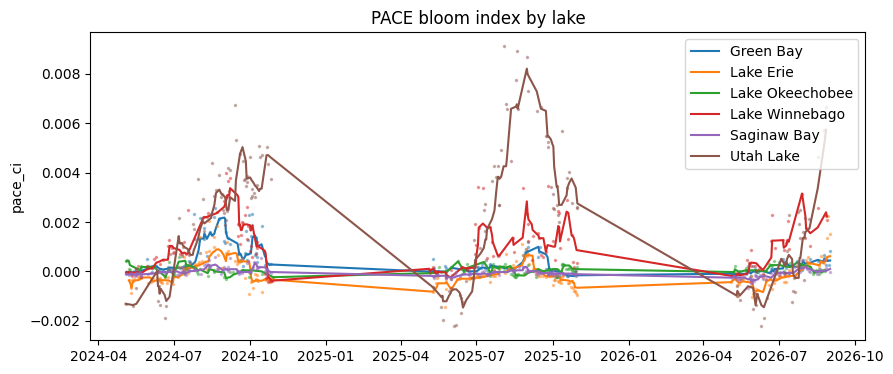

In [25]:
# ------------------------------------------------------------------
# Look at the bloom index over time, one line per lake
# ------------------------------------------------------------------
# Dots are single clear days (median across a lake's points); lines are a 14-day
# rolling median. Expect a rise through mid/late summer in bloom-prone lakes.
fig, ax = plt.subplots(figsize=(10, 4))
for lake, grp in pace_obs.groupby("lake"):
    daily = grp.groupby("date")[TARGET_INDEX].median().sort_index() # median across the lake's points, per day
    line, = ax.plot(daily.rolling("14D").median(), label=lake) # smoothed line: 14-day rolling median
    ax.plot(daily.index, daily.values, ".", ms=3, alpha=0.4, color=line.get_color()) # daily dots, same colour
ax.set_ylabel(TARGET_INDEX)
ax.set_title("PACE bloom index by lake")
ax.legend()
plt.show()

### Sentinel-2: the latest clear image at each point, every few days

CyFi is asked for the latest image at each point every `S2_QUERY_EVERY_DAYS` days. For each request it returns features from the most recent clear image on or before that day, and the image's actual date is recorded. Results are saved in `s2_obs_chunks/`, one file per month, so interrupted runs resume and adding a season only downloads the new months.

In [26]:
# ------------------------------------------------------------------
# Sentinel-2: the latest clear image at each point, every few days (via CyFi)
# ------------------------------------------------------------------
import hashlib
import time
import cyfi.data.satellite_data as cyfi_sat

# An earlier version of this notebook replaced one of CyFi's functions. Put the
# original back in case it's still active in this Python session.
if hasattr(cyfi_sat, "_original_select_items"):
    cyfi_sat.select_items = cyfi_sat._original_select_items

# Request days: every S2_QUERY_EVERY_DAYS days, from a little before each season
# (to cover the lead time) to LEAD_DAYS before its end
s2_days = pd.DatetimeIndex(sorted(set().union(*[
    pd.date_range(pd.Timestamp(s) - pd.Timedelta(days=LEAD_DAYS + S2_QUERY_EVERY_DAYS),
                  pd.Timestamp(e) - pd.Timedelta(days=LEAD_DAYS),
                  freq=f"{S2_QUERY_EVERY_DAYS}D")
    for s, e in SEASONS
])))
s2_grid = point_day_grid(s2_days)

s2_pipe = CyFiPipeline(features_config=baseline_pipeline.features_config, cache_dir="cyfi_cache")

s2_dir = Path("s2_obs_chunks"); s2_dir.mkdir(exist_ok=True)
feat_parts, meta_parts = [], []

# File name includes a fingerprint of that month's points
# and days, so changing the lakes/settings never reuses mismatched results.
for month, chunk in s2_grid.groupby(pd.to_datetime(s2_grid["date"]).dt.strftime("%Y-%m")):
    key = hashlib.md5("".join(sorted(chunk.index)).encode()).hexdigest()[:8]
    f_csv, m_csv = s2_dir / f"s2_{month}_{key}.csv", s2_dir / f"meta_{month}_{key}.csv"

    if f_csv.exists():
        feat_parts.append(pd.read_csv(f_csv, index_col="sample_id"))
        meta_parts.append(pd.read_csv(m_csv, index_col="sample_id"))
        continue

    status = "failed" # becomes "ok" or "empty" if an attempt finishes
    for attempt in range(5):   # up to 5 tries, waiting longer each time
        try:
            feats = s2_pipe._prepare_features(chunk[["date", "latitude", "longitude"]], train_split=True)
            # CyFi also saves which image it used (days_before_sample = how many
            # days before the request day that image was taken)
            meta = pd.read_csv(s2_pipe.cache_dir / "sentinel_metadata_train.csv", index_col="sample_id")
            status = "ok"
            break
        except SystemExit: # CyFi calls exit(1) when nothing in the chunk has usable imagery
            status = "empty"
            break
        except Exception as e:
            if isinstance(e, ValueError) and "No objects to concatenate" in str(e): # no scenes at all
                status = "empty"
                break
            wait = 30 * (2 ** attempt)
            print(f"S2 {month} attempt {attempt + 1} failed ({type(e).__name__}); sleeping {wait}s")
            time.sleep(wait)

    if status == "failed": # save nothing, so the next run retries this month
        print(f"S2 {month} gave up; rerun this cell to retry it")
        continue
    if status == "empty": # save an empty result so the next run skips this month
        print(f"S2 {month}: no usable Sentinel-2 imagery")
        feats = pd.DataFrame(index=pd.Index([], name="sample_id"))
        meta = pd.DataFrame(index=pd.Index([], name="sample_id"))
    feats.to_csv(f_csv)
    meta.to_csv(m_csv)
    feat_parts.append(feats)
    meta_parts.append(meta)
    time.sleep(5)

s2_raw = pd.concat([p for p in feat_parts if len(p)])
s2_meta = pd.concat([p for p in meta_parts if len(p)])

# Pretrained CyFi's estimate for each image (log cell density), a useful summary input.
# Computed before dropping columns because model_v0 expects all of CyFi's features.
s2_raw["cyfi_pretrained_pred"] = np.clip(
    np.mean([m.predict(s2_raw[m.feature_name()]) for m in baseline_pipeline.models], axis=0), 0, None
)

# Drop days_before_sample (relative to the request day, meaningless here) and add point_id
s2_obs = s2_raw.drop(columns=["days_before_sample"], errors="ignore").join(s2_grid[["point_id"]])
# The image's actual date = request day minus how many days earlier the image was taken
s2_obs["image_date"] = (pd.to_datetime(s2_grid.loc[s2_obs.index, "date"])
                        - pd.to_timedelta(s2_meta.loc[s2_obs.index, "days_before_sample"], unit="D"))

# Several request days can return the same image; keep each image once per point
s2_obs = s2_obs.sort_values("image_date").drop_duplicates(["point_id", "image_date"]).reset_index(drop=True)
print(f"{len(s2_obs):,} distinct Sentinel-2 images across {s2_obs['point_id'].nunique()} points")

647 distinct Sentinel-2 images across 13 points


### Build the forecast table

One row per point per forecast day that has a clear PACE view (the answer). For each row, the inputs are the most recent PACE and Sentinel-2 observations taken on or before the **cutoff**, which is `LEAD_DAYS` before the forecast day. 

In [27]:
# ------------------------------------------------------------------
# Build the forecast table: inputs from >= LEAD_DAYS before, answer on the day
# ------------------------------------------------------------------
# The answer: PACE's bloom index at each point on each forecast day with a clear view
forecast = pace_obs.loc[pace_obs["date"].isin(target_days), ["point_id", "lake", "date", TARGET_INDEX]]
forecast = forecast.rename(columns={TARGET_INDEX: "target"}).reset_index(drop=True)

# Inputs may only come from on or before this date
forecast["cutoff"] = forecast["date"] - pd.Timedelta(days=LEAD_DAYS)

# --- PACE inputs: the latest clear PACE view on or before the cutoff ---
pace_input_cols = [c for c in pace_obs.columns if c.startswith("pace_")] # all PACE feature columns
pace_hist = (pace_obs[["point_id", "date"] + pace_input_cols]
             .rename(columns={"date": "pace_date"}).sort_values("pace_date")) # PACE history sorted
# merge_asof: for each row, the latest PACE view at the same point on or before the
# cutoff, at most PACE_LOOKBACK_DAYS older (otherwise left empty)
forecast = pd.merge_asof(
    forecast.sort_values("cutoff"), pace_hist,
    left_on="cutoff", right_on="pace_date", by="point_id",
    direction="backward", tolerance=pd.Timedelta(days=PACE_LOOKBACK_DAYS),
)
forecast["pace_age_days"] = (forecast["date"] - forecast["pace_date"]).dt.days # how old that view is

# --- PACE trend inputs: average and count of clear views over the 14 days up to the cutoff
daily = pace_obs.pivot_table(index="date", columns="point_id", values=TARGET_INDEX) # rows = days, columns = points
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max())) # every calendar day (gaps = NaN)
recent = pd.concat([
    daily.rolling(14, min_periods=1).mean().stack().rename("pace_recent_mean_14d"), # 14-day average (skips gaps)
    daily.notna().rolling(14, min_periods=1).sum().stack().rename("pace_recent_views_14d"), # clear views in those 14 days
], axis=1)
recent.index.names = ["cutoff", "point_id"]
forecast = forecast.merge(recent.reset_index(), on=["cutoff", "point_id"], how="left") 

# --- Sentinel-2 inputs: the latest image on or before the cutoff (within S2_LOOKBACK_DAYS) ---
s2_input_cols = [c for c in s2_obs.columns if c not in ("point_id", "image_date")] # all Sentinel-2 feature columns
s2_hist = s2_obs.rename(columns={"image_date": "s2_date"}).sort_values("s2_date") # Sentinel-2 history sorted
forecast = pd.merge_asof(
    forecast.sort_values("cutoff"), s2_hist,
    left_on="cutoff", right_on="s2_date", by="point_id",
    direction="backward", tolerance=pd.Timedelta(days=S2_LOOKBACK_DAYS),
)
forecast["s2_age_days"] = (forecast["date"] - forecast["s2_date"]).dt.days # how old that view is

# --- Calendar input: time of year is known in advance, so it's fair to use
forecast["day_of_year"] = forecast["date"].dt.dayofyear

# Keep rows with inputs from both satellites
has_pace, has_s2 = forecast["pace_date"].notna(), forecast["s2_date"].notna()
print(f"Forecast days with a clear PACE answer: {len(forecast):,}")
print(f"  ...with PACE inputs: {has_pace.sum():,}   with Sentinel-2 inputs: {has_s2.sum():,}   with both: {(has_pace & has_s2).sum():,}")
forecast = forecast[has_pace & has_s2].sort_values(["point_id", "date"]).reset_index(drop=True)

# Checks no input may be newer than the cutoff
assert (forecast["pace_age_days"] >= LEAD_DAYS).all() and (forecast["s2_age_days"] >= LEAD_DAYS).all()

# The input columns for each satellite
CALENDAR = ["day_of_year"]
PACE_FEATURES = pace_input_cols + ["pace_age_days", "pace_recent_mean_14d", "pace_recent_views_14d"]
S2_FEATURES = s2_input_cols + ["s2_age_days"]
print(f"{len(forecast):,} rows from {forecast['point_id'].nunique()} points in {forecast['lake'].nunique()} lakes")

Forecast days with a clear PACE answer: 1,730
  ...with PACE inputs: 1,601   with Sentinel-2 inputs: 1,722   with both: 1,593
1,593 rows from 13 points in 6 lakes


### Compare models against simple baselines

All models are scored on the same rows with cross-validation.

- **Predict training mean:** the floor any model must beat.
- **Persistence:** "the index will be the same as the last PACE view." Blooms persist for weeks, so this is the real benchmark for a forecast.
- **Recent average:** the average of the last 14 days of PACE views.
- **S2 only / PACE only / S2 + PACE:** LightGBM models (the same type CyFi uses) with each satellite's inputs.

Metrics: **R²** (1 = perfect, 0 = no better than the mean), **RMSE** (typical error, in index units), and **bloom F1**, which measures how well a model flags the top quarter of index values ("bloom" days); 1 = perfect.

In [30]:
# ------------------------------------------------------------------
# Compare models against baselines with week-grouped cross-validation
# ------------------------------------------------------------------
import lightgbm as lgb # boosted decision trees (CyFi's model type)
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, root_mean_squared_error, f1_score

FEATURE_SETS = {
    "S2 only": S2_FEATURES + CALENDAR,
    "PACE only": PACE_FEATURES + CALENDAR,
    "S2 + PACE": S2_FEATURES + PACE_FEATURES + CALENDAR,
}

# LightGBM settings for a modest dataset
LGB_PARAMS = dict(
    n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=10, # 300 small trees, learning slowly
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, # random 80% of rows/columns per tree; mild penalty
    random_state=40, verbose=-1, # repeatable; no training messages
)

y = forecast["target"] # the answers

# "Bloom" days for the F1 score = the top 25% of index values
BLOOM_THRESHOLD = y.quantile(0.75)

# Cross-validation groups: ISO calendar week, e.g. "2025-W31"
weeks = forecast["date"].dt.strftime("%G-W%V")
N_SPLITS = min(5, weeks.nunique())


def grouped_cv_predict(X):
    # Out-of-fold predictions: each week is predicted by a model trained on the other weeks
    oof = pd.Series(np.nan, index=X.index)
    for tr, va in GroupKFold(n_splits=N_SPLITS).split(X, y, weeks): # tr = training rows, va = held-out rows
        model = lgb.LGBMRegressor(**LGB_PARAMS).fit(X.iloc[tr], y.iloc[tr]) # train on the other weeks
        oof.iloc[va] = model.predict(X.iloc[va]) # predict the held-out weeks
    return oof


def score(y_true, pred):
    pred = pd.Series(np.asarray(pred, dtype=float), index=y_true.index)
    return {
        "R²": r2_score(y_true, pred),  # share of variation explained (1 = perfect)
        "RMSE": root_mean_squared_error(y_true, pred), # typical error, in index units
        "bloom F1": f1_score(y_true > BLOOM_THRESHOLD, pred > BLOOM_THRESHOLD, zero_division=0), # bloom-day detection (1 = perfect)
    }


results = {}

# Baseline: each week gets the average of the other weeks
mean_pred = pd.Series(np.nan, index=y.index)
for tr, va in GroupKFold(n_splits=N_SPLITS).split(forecast, y, weeks):
    mean_pred.iloc[va] = y.iloc[tr].mean()
results["Predict training mean"] = score(y, mean_pred)

# Baselines built from PACE's own history
results["Persistence (last PACE view)"] = score(y, forecast[TARGET_INDEX]) # same as the last view
results["Recent average (14 days)"] = score(y, forecast["pace_recent_mean_14d"]) # average of the last 14 days

# The models
oof_preds = {}
for name, cols in FEATURE_SETS.items():
    oof_preds[name] = grouped_cv_predict(forecast[cols])
    results[name] = score(y, oof_preds[name])

results_df = pd.DataFrame(results).T  # table: rows = models, columns = metrics
print(f"{len(forecast):,} forecasts, {N_SPLITS}-fold CV grouped by week, {LEAD_DAYS} days ahead")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(results_df)

1,593 forecasts, 5-fold CV grouped by week, 7 days ahead


,R²,RMSE,bloom F1
Predict training mean,-0.00488,0.00119,0
Persistence (last PACE view),0.542,0.000806,0.711
Recent average (14 days),0.589,0.000763,0.704
S2 only,0.721,0.000628,0.745
PACE only,0.72,0.00063,0.74
S2 + PACE,0.733,0.000615,0.765


## Train on the other lakes, test on each lake in turn

In [31]:
# Shows whether the model works on a lake it never saw. R² can be very negative
# for a lake with little variation, so compare each model with Persistence.
lakes = forecast["lake"]
if lakes.nunique() > 1:
    transfer = {}
    for lake in lakes.unique(): # each lake takes a turn as the test lake
        tr, te = lakes != lake, lakes == lake # train on the others, test on this one
        row = {"forecasts": int(te.sum()), "Persistence": r2_score(y[te], forecast.loc[te, TARGET_INDEX])}
        for name, cols in FEATURE_SETS.items():
            model = lgb.LGBMRegressor(**LGB_PARAMS).fit(forecast.loc[tr, cols], y[tr]) # train without this lake
            row[name] = r2_score(y[te], model.predict(forecast.loc[te, cols]))# score on this lake
        transfer[lake] = row
    transfer_df = pd.DataFrame(transfer).T.round(3)
    transfer_df["forecasts"] = transfer_df["forecasts"].astype(int)
    print("R² on each lake when trained only on the other lakes:")
    display(transfer_df)
else:
    print("Only one lake with data; add lakes in the settings cell to test transfer.")

R² on each lake when trained only on the other lakes:


,forecasts,Persistence,S2 only,PACE only,S2 + PACE
Green Bay,121,0.002,-0.030,0.093,-0.182
Lake Erie,1002,0.062,-0.611,0.012,0.060
Lake Okeechobee,91,-0.948,-51.857,-14.458,-26.276
Lake Winnebago,90,-0.658,-0.466,-0.155,-0.196
Saginaw Bay,157,-0.799,-1.682,-1.528,-0.641
Utah Lake,132,0.466,-0.298,-0.340,-0.256


In [32]:
# Scores within each lake, using the cross-validated forecasts. This looks at when the current lake also takes in data from its previous weeks
per_lake = {}
for lake, idx in forecast.groupby("lake").groups.items():
    per_lake[lake] = {
        "rows": len(idx),
        "Persistence": r2_score(y[idx], forecast.loc[idx, TARGET_INDEX]),
        "Recent average": r2_score(y[idx], forecast.loc[idx, "pace_recent_mean_14d"]),
        **{name: r2_score(y[idx], oof_preds[name][idx]) for name in FEATURE_SETS},
    }
per_lake_df = pd.DataFrame(per_lake).T.round(3)
per_lake_df["rows"] = per_lake_df["rows"].astype(int)
display(per_lake_df)

,rows,Persistence,Recent average,S2 only,PACE only,S2 + PACE
Green Bay,121,0.002,0.179,0.343,0.371,0.301
Lake Erie,1002,0.062,0.077,0.395,0.448,0.494
Lake Okeechobee,91,-0.948,-0.462,-2.164,-1.065,-1.121
Lake Winnebago,90,-0.658,-0.253,0.002,0.138,0.111
Saginaw Bay,157,-0.799,0.024,-0.234,-0.338,-0.140
Utah Lake,132,0.466,0.526,0.703,0.650,0.672


## Train on earlier seasons, test on the latest one

In [33]:
# ------------------------------------------------------------------
# Year check: train on earlier seasons, test on the latest one
# ------------------------------------------------------------------
# Closest to real use: a model built on past seasons forecasting a new one
years = forecast["date"].dt.year
if years.nunique() > 1:
    test_year = years.max()
    tr, te = years < test_year, years == test_year
    by_year = {"Persistence (last PACE view)": score(y[te], forecast.loc[te, TARGET_INDEX])}
    for name, cols in FEATURE_SETS.items():
        model = lgb.LGBMRegressor(**LGB_PARAMS).fit(forecast.loc[tr, cols], y[tr])
        by_year[name] = score(y[te], model.predict(forecast.loc[te, cols]))
    print(f"Train on {sorted(int(v) for v in years[tr].unique())} (n={tr.sum():,}), test on {test_year} (n={te.sum():,})")
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(pd.DataFrame(by_year).T)
else:
    print("Only one season so far; add seasons in the settings cell to run this check.")

Train on [2024, 2025] (n=1,291), test on 2026 (n=302)


,R²,RMSE,bloom F1
Persistence (last PACE view),0.354,0.000719,0.667
S2 only,0.348,0.000722,0.627
PACE only,0.513,0.000624,0.662
S2 + PACE,0.445,0.000666,0.709


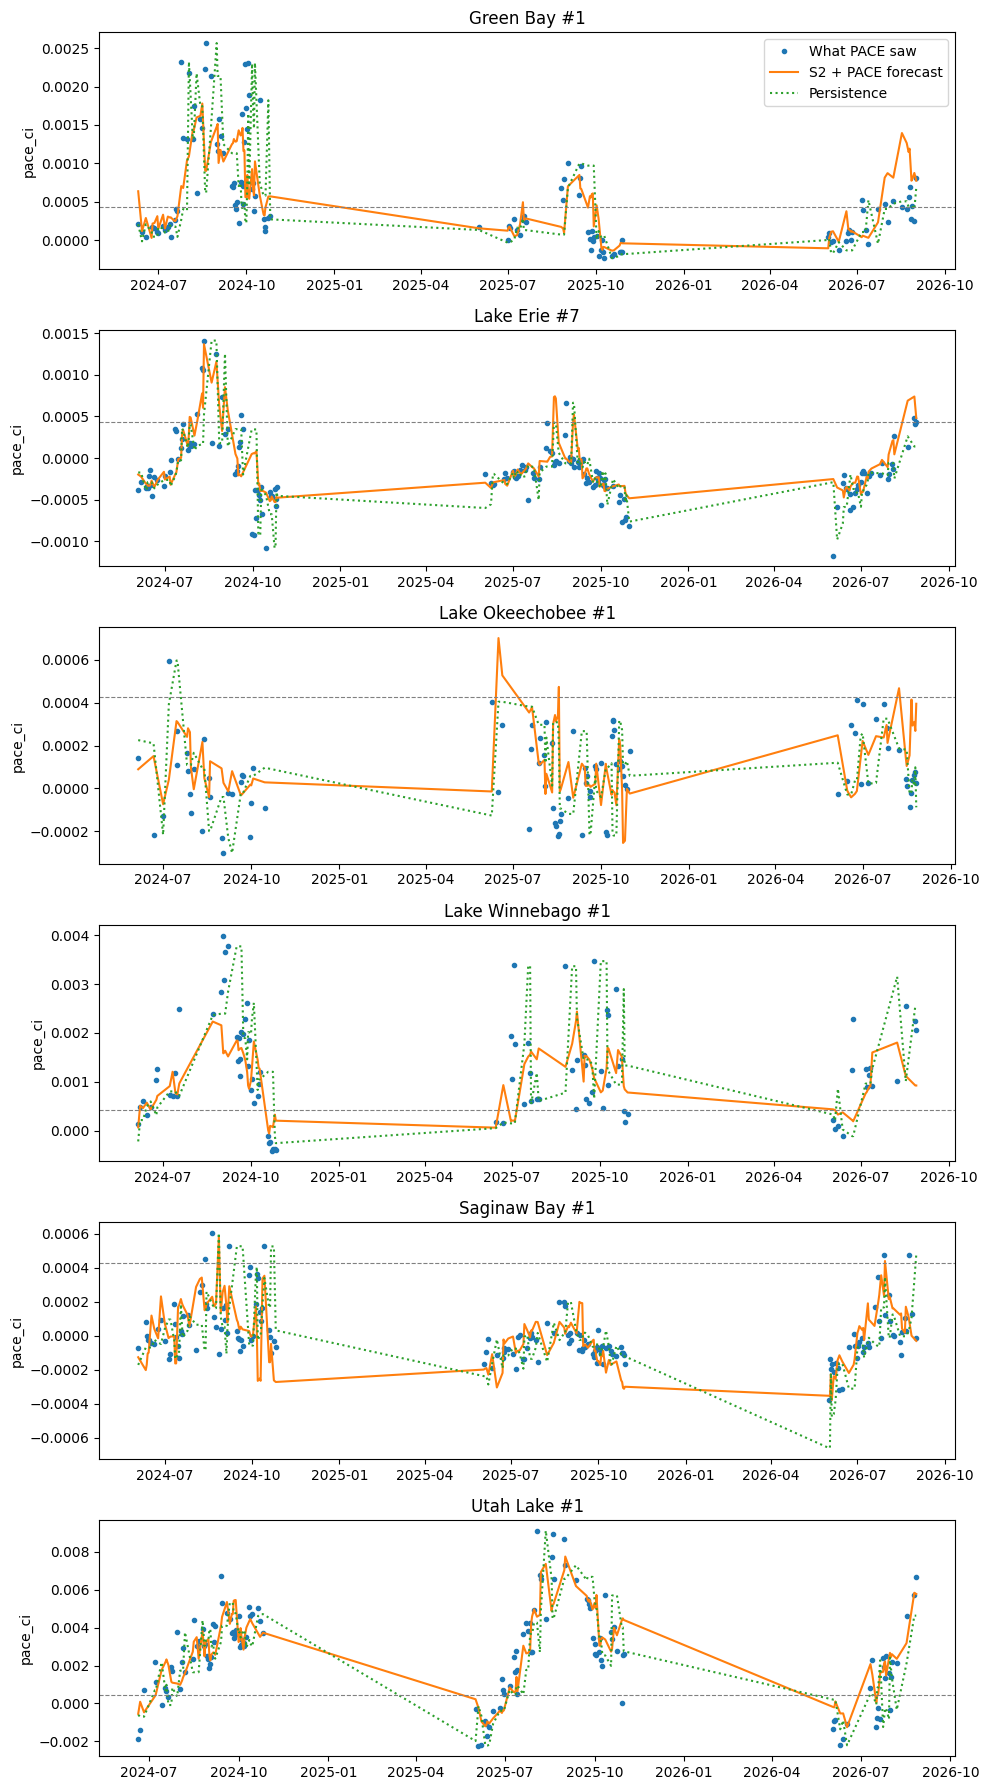

In [34]:
# ------------------------------------------------------------------
# Forecasts vs. what PACE saw: the busiest point in each lake
# ------------------------------------------------------------------
lake_points = forecast.groupby("lake")["point_id"].agg(lambda s: s.value_counts().idxmax()) # busiest point per lake
fig, axes = plt.subplots(len(lake_points), 1, figsize=(10, 3 * len(lake_points))) # one panel per lake, stacked

for ax, (lake, point) in zip(axes, lake_points.items()):
    sel = forecast["point_id"] == point # this point's rows
    ax.plot(forecast.loc[sel, "date"], y[sel], "o", ms=3, label="What PACE saw") # dots: the answers
    ax.plot(forecast.loc[sel, "date"], oof_preds["S2 + PACE"][sel], "-", label="S2 + PACE forecast") # line: forecasts
    ax.plot(forecast.loc[sel, "date"], forecast.loc[sel, TARGET_INDEX], ":", label="Persistence") # dotted: persistence
    ax.axhline(BLOOM_THRESHOLD, color="grey", lw=0.8, ls="--") # bloom threshold
    ax.set_title(point)
    ax.set_ylabel(TARGET_INDEX)

axes[0].legend()      # one legend is enough
plt.tight_layout()    # stop panels overlapping
plt.show()

### Final model

Refits the feature set with the lowest cross-validated RMSE on all rows and saves it, with the lead time in the file name.

Saved 'S2 + PACE' model (7-day lead, 1,593 rows) to satellite_forecast_lead7.txt


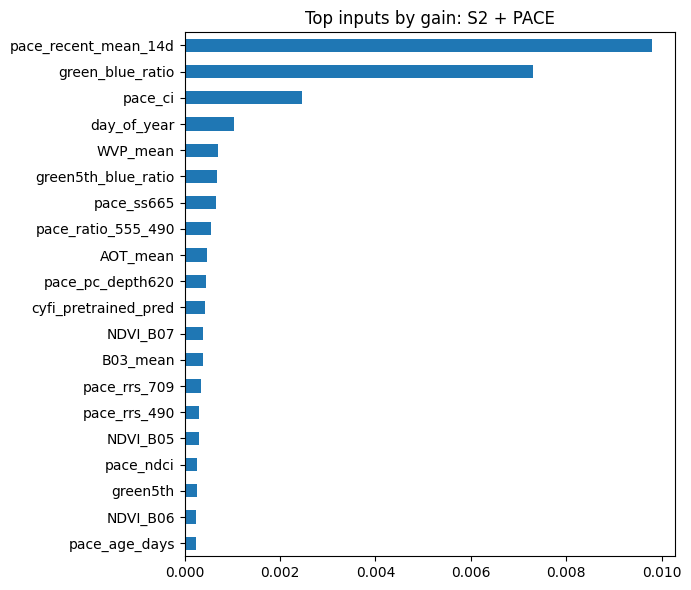

In [35]:
# ------------------------------------------------------------------
# Train the final model on all rows and save it
# ------------------------------------------------------------------
import json

# Lowest cross-validated error among the models (baselines excluded)
best_set = results_df.loc[list(FEATURE_SETS), "RMSE"].idxmin()
final_cols = FEATURE_SETS[best_set]

# Cross-validation was only for scoring; the final model learns from every row
final_model = lgb.LGBMRegressor(**LGB_PARAMS).fit(forecast[final_cols], y)

# Save the trees (reload with lgb.Booster(model_file=...))
model_file = f"satellite_forecast_lead{LEAD_DAYS}.txt"
final_model.booster_.save_model(model_file)
# Save the settings needed to reuse the model correctly (inputs in order, lead time, target...)
with open(f"satellite_forecast_lead{LEAD_DAYS}_meta.json", "w") as f:
    json.dump(
        {
            "target_index": TARGET_INDEX,
            "lead_days": LEAD_DAYS,
            "pace_lookback_days": PACE_LOOKBACK_DAYS,
            "s2_lookback_days": S2_LOOKBACK_DAYS,
            "feature_set": best_set,
            "features": final_cols,
            "bloom_threshold": float(BLOOM_THRESHOLD),
            "lakes": LAKES,
            "seasons": SEASONS,
            "n_train": int(len(forecast)),
        },
        f,
        indent=2,
    )
print(f"Saved '{best_set}' model ({LEAD_DAYS}-day lead, {len(forecast):,} rows) to {model_file}")

# Feature importance by "gain": how much each input reduced the error across all trees. 
# Shows which satellite the model leans on.
importance = pd.Series(final_model.booster_.feature_importance("gain"), index=final_cols).sort_values()
importance.tail(20).plot(kind="barh", figsize=(7, 6), title=f"Top inputs by gain: {best_set}")
plt.tight_layout()
plt.show()

### What the feature importance shows

The bars show how much each input reduced the model's forecast error across all its trees ("gain"). Longer bars mean the model relied on that input more.

- **`pace_recent_mean_14d`** (PACE's average bloom index over the last two weeks) matters most. Recent bloom history is the strongest clue to next week's bloom, which fits the 14-day average being the best simple baseline.
- **`green_blue_ratio`** (Sentinel-2) is a close second. Greener water relative to blue is a classic sign of algae, and Sentinel-2's fine detail adds information PACE's history doesn't.
- **`pace_ci`** (the latest single PACE view) and **`day_of_year`** (the season) come next.
- Everything else contributes only a little each. `WVP_mean` (water vapour) and `AOT_mean` (haze) describe the atmosphere, not the water. They may stand in for weather or season, so treat their role with caution.

**Takeaway:** the two most important inputs come from different satellites, so the combined model uses both PACE and Sentinel-2 rather than relying on one. Importance shows what this model leans on, not what causes blooms.

# **Bloom risk warnings: 1, 3 and 7 days ahead, with weather**

The project's aim is a warning people can act on: *is a bloom likely at this spot in the next few days?* The forecast above predicts PACE's bloom index 7 days ahead from satellite inputs alone. This part adds:

1. **Weather.** Daily air temperature, wind, rain and sunlight at each point, from NASA POWER. Warm, calm, sunny spells grow blooms and wind mixes or moves them, so weather should matter most at short lead times.
2. **Shorter lead times.** The same forecast is built 1, 3 and 7 days ahead, to see how skill changes with lead time.
3. **Risk instead of an index value.** A second model gives the chance (0 to 100%) that a day will be a bloom day, which is turned into Low / Moderate / High.
4. **An outlook table.** The risk at every point for the days after the latest data, which is what a warning would look like.

A "bloom day" is defined as above: PACE's index in the top quarter of all values (`BLOOM_THRESHOLD`). That is a relative level.

**Run the cells above first** (through the Sentinel-2 + PACE forecast).

In [36]:
# ------------------------------------------------------------------
# Bloom-risk settings: lead times, weather inputs and risk levels
# ------------------------------------------------------------------
import requests
from functools import reduce

RISK_LEADS = [1, 3, 7]     # how many days ahead to warn
WEATHER_WINDOWS = [3, 7]   # summarise the weather over the 3 and 7 days up to the day the forecast is made

# Daily weather from NASA POWER: its name -> (our name, how to summarise it over several days)
WEATHER_VARS = {
    "T2M": ("air_temp", "mean"),              # average air temperature (°C); stands in for water temperature
    "T2M_MAX": ("air_temp_max", "max"),       # hottest it got (°C)
    "WS10M": ("wind", "mean"),                # average wind speed (m/s)
    "WS10M_MAX": ("wind_max", "max"),         # strongest wind (m/s)
    "PRECTOTCORR": ("rain", "sum"),           # total rainfall (mm)
    "ALLSKY_SFC_SW_DWN": ("sunlight", "mean"),   # sunlight reaching the surface
}

WARN_AT = 0.5   # a warning is issued when the bloom risk reaches 50%
RISK_LEVELS = {"Low": 0.0, "Moderate": 0.3, "High": 0.6}   # each level starts at this risk

print(f"Lead times: {RISK_LEADS} days; {len(WEATHER_VARS)} weather variables over {WEATHER_WINDOWS}-day windows; "
      f"bloom day = {TARGET_INDEX} above {BLOOM_THRESHOLD:.3g}")

Lead times: [1, 3, 7] days; 6 weather variables over [3, 7]-day windows; bloom day = pace_ci above 0.000428


### Weather: daily values at each point

NASA POWER gives daily weather for any latitude and longitu. . One request per point covers every season. Results are saved in `weather_cache/` (delete that folder to fetch fresh values).

POWER's grid is coarse (roughly 50 km), so this is the weather of the area around the lake, not of the exact point. Recent days can arrive two or more days late, and missing values are left empty.

In [37]:
# ------------------------------------------------------------------
# Weather: daily NASA POWER values at each point
# ------------------------------------------------------------------
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
weather_dir = Path("weather_cache"); weather_dir.mkdir(exist_ok=True)

# Days needed: from 45 days before the first season (so early forecasts have weather
# history) to the end of the last one, but never later than two days ago
wx_start = min(pd.Timestamp(s) for s, _ in SEASONS) - pd.Timedelta(days=45)
wx_end = min(max(pd.Timestamp(e) for _, e in SEASONS), pd.Timestamp.today().normalize() - pd.Timedelta(days=2))


def fetch_weather(lat, lon):
    # Daily weather at one place: one row per day, one column per variable
    csv = weather_dir / f"power_{lat}_{lon}_{wx_start:%Y%m%d}_{wx_end:%Y%m%d}.csv"
    if csv.exists():
        return pd.read_csv(csv, index_col=0, parse_dates=True)

    for attempt in range(5):   # up to 5 tries, waiting longer each time
        try:
            resp = requests.get(POWER_URL, timeout=120, params={
                "parameters": ",".join(WEATHER_VARS),
                "community": "RE",   # which of POWER's parameter catalogues to use
                "latitude": lat, "longitude": lon,
                "start": wx_start.strftime("%Y%m%d"), "end": wx_end.strftime("%Y%m%d"),
                "format": "JSON",
            })
            resp.raise_for_status()
            values = resp.json()["properties"]["parameter"]   # {variable: {"20240601": value, ...}}
            break
        except Exception as e:
            wait = 30 * (2 ** attempt)
            print(f"Weather at ({lat}, {lon}) attempt {attempt + 1} failed ({type(e).__name__}); sleeping {wait}s")
            time.sleep(wait)
    else:
        raise RuntimeError(f"Couldn't fetch weather at ({lat}, {lon}); rerun this cell to retry")

    daily = pd.DataFrame(values).rename(columns={k: v[0] for k, v in WEATHER_VARS.items()})
    daily.index = pd.to_datetime(daily.index, format="%Y%m%d")   # "20240601" -> real date
    daily = daily.replace(-999, np.nan)   # POWER marks missing values as -999
    daily.to_csv(csv)
    return daily


# Fetch every point and stack into one table: one row per point per day
weather_parts = []
for p in points.itertuples():
    daily = fetch_weather(p.latitude, p.longitude)
    weather_parts.append(daily.rename_axis("date").reset_index().assign(point_id=p.point_id))
weather = pd.concat(weather_parts, ignore_index=True)
weather["date"] = weather["date"].astype("datetime64[ns]")

wx_names = [name for name, _ in WEATHER_VARS.values()]
print(f"{len(weather):,} point/days of weather, {weather['date'].min():%Y-%m-%d} to {weather['date'].max():%Y-%m-%d}")
print("Share of values missing:")
print(weather[wx_names].isna().mean().round(3).to_string())

11,635 point/days of weather, 2024-04-17 to 2026-09-28
Share of values missing:
air_temp        0.000
air_temp_max    0.000
wind            0.000
wind_max        0.000
rain            0.000
sunlight        0.002


### Build one forecast table per lead time

The same table as above, built once for each lead time. For a forecast made on the **cutoff** day (`lead` days before the forecast day), the inputs are:

- **PACE and Sentinel-2:** the latest clear views on or before the cutoff, exactly as above.
- **Weather so far:** each weather variable summarised over the 3 and 7 days up to the cutoff. These are known when the forecast is made.
- **Weather to come:** the same variables over the days between the cutoff and the forecast day. In real use these would come from a weather forecast. Here the weather that actually happened is used, so a model with these inputs shows the *most* a perfect weather forecast could add.

Only point/days that have a row at every lead time are kept, so the lead times are compared on exactly the same days. That is why the 7-day numbers differ slightly from the table above.

In [38]:
# ------------------------------------------------------------------
# Build the forecast table for any lead time, with weather inputs
# ------------------------------------------------------------------
def recent_history(obs, value_col, prefix):
    # For every point and day: the average and the number of clear views over the
    # 14 days up to that day (the same calculation as the PACE trend inputs above)
    daily = obs.pivot_table(index="date", columns="point_id", values=value_col)   # rows = days, columns = points
    daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()))    # every calendar day (gaps = NaN)
    out = pd.concat([
        daily.rolling(14, min_periods=1).mean().stack().rename(f"{prefix}_recent_mean_14d"),           # 14-day average (skips gaps)
        daily.notna().rolling(14, min_periods=1).sum().stack().rename(f"{prefix}_recent_views_14d"),   # clear views in those 14 days
    ], axis=1)
    out.index.names = ["cutoff", "point_id"]
    out = out.reset_index()
    out["cutoff"] = out["cutoff"].astype("datetime64[ns]")
    return out


def latest_before_cutoff(table, history, date_col, lookback_days):
    # For each row, attach the latest observation at the same point on or before the
    # cutoff, at most lookback_days older (otherwise left empty)
    history = history.sort_values(date_col)
    history[date_col] = history[date_col].astype("datetime64[ns]")               # same date type on both sides
    history["point_id"] = history["point_id"].astype(table["point_id"].dtype)   # same text type on both sides
    return pd.merge_asof(
        table.sort_values("cutoff"), history,
        left_on="cutoff", right_on=date_col, by="point_id",
        direction="backward", tolerance=pd.Timedelta(days=lookback_days),
    )


def weather_summary(days, day_col, name):
    # Every weather variable summarised over the `days` days ending on each day.
    # day_col = the column it will be matched on; name(variable) = the new column's name
    parts = []
    for var, how in WEATHER_VARS.values():
        wide = weather.pivot(index="date", columns="point_id", values=var)   # rows = days, columns = points
        wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max()))
        rolled = getattr(wide.rolling(days, min_periods=1), how)()   # e.g. the 3-day mean, max or sum
        parts.append(rolled.stack().rename(name(var)))
    out = pd.concat(parts, axis=1)
    out.index.names = [day_col, "point_id"]
    out = out.reset_index()
    out[day_col] = out[day_col].astype("datetime64[ns]")
    return out


def build_lead_table(lead, rows=None, keep_all=False):
    # One row per point per forecast day, with inputs from at least `lead` days earlier.
    # rows = the point/days to forecast (default: every forecast day with a clear PACE answer).
    # keep_all=True keeps rows whose satellite inputs are missing.
    if rows is None:
        # The answer: PACE's bloom index at each point on each forecast day with a clear view
        table = pace_obs.loc[pace_obs["date"].isin(target_days), ["point_id", "lake", "date", TARGET_INDEX]]
        table = table.rename(columns={TARGET_INDEX: "target"}).reset_index(drop=True)
    else:
        table = rows.copy()
    table["date"] = table["date"].astype("datetime64[ns]")

    # Inputs may only come from on or before this date
    table["cutoff"] = table["date"] - pd.Timedelta(days=lead)

    # --- PACE inputs: the latest clear view on or before the cutoff, and the 14-day trend ---
    pace_history = pace_obs[["point_id", "date"] + pace_input_cols].rename(columns={"date": "pace_date"})
    table = latest_before_cutoff(table, pace_history, "pace_date", PACE_LOOKBACK_DAYS)
    table["pace_age_days"] = (table["date"] - table["pace_date"]).dt.days   # how old that view is
    table = table.merge(recent_history(pace_obs, TARGET_INDEX, "pace"), on=["cutoff", "point_id"], how="left")

    # --- Sentinel-2 inputs: the latest image on or before the cutoff ---
    # (images were requested with the 7-day forecast in mind, so in the last few days of
    # a season the shorter lead times use a slightly older image than they could)
    s2_history = s2_obs.rename(columns={"image_date": "s2_date"})
    table = latest_before_cutoff(table, s2_history, "s2_date", S2_LOOKBACK_DAYS)
    table["s2_age_days"] = (table["date"] - table["s2_date"]).dt.days

    # --- Calendar input ---
    table["day_of_year"] = table["date"].dt.dayofyear

    # --- Weather so far: each variable over the 3 and 7 days up to the cutoff ---
    for window in WEATHER_WINDOWS:
        so_far = weather_summary(window, "cutoff", lambda var: f"wx_{var}_{window}d")
        table = table.merge(so_far, on=["cutoff", "point_id"], how="left")

    # --- Weather to come: each variable over the `lead` days ending on the forecast day ---
    to_come = weather_summary(lead, "date", lambda var: f"wxnext_{var}")
    table = table.merge(to_come, on=["date", "point_id"], how="left")

    if not keep_all:   # keep rows with inputs from both satellites, as above
        table = table[table["pace_date"].notna() & table["s2_date"].notna()]
        assert (table["pace_age_days"] >= lead).all() and (table["s2_age_days"] >= lead).all()   # nothing newer than the cutoff
    return table.sort_values(["point_id", "date"]).reset_index(drop=True)


lead_tables = {lead: build_lead_table(lead) for lead in RISK_LEADS}
print("Rows with inputs, by lead time:", {f"{lead}-day": len(t) for lead, t in lead_tables.items()})

# Keep only point/days present at every lead time, so all lead times are scored on the same days
shared = reduce(lambda a, b: a.merge(b), [t[["point_id", "date"]] for t in lead_tables.values()])
lead_tables = {lead: t.merge(shared).sort_values(["point_id", "date"]).reset_index(drop=True)
               for lead, t in lead_tables.items()}

# The same for every lead time, because the rows are the same
risk_y = lead_tables[RISK_LEADS[0]]["target"]                        # the answers: PACE's index on the day
risk_bloom = risk_y > BLOOM_THRESHOLD                                # True on bloom days
risk_weeks = lead_tables[RISK_LEADS[0]]["date"].dt.strftime("%G-W%V")   # cross-validation groups
RISK_N_SPLITS = min(5, risk_weeks.nunique())

# The input columns
WEATHER_FEATURES = [f"wx_{var}_{window}d" for window in WEATHER_WINDOWS for var in wx_names]
NEXT_WEATHER_FEATURES = [f"wxnext_{var}" for var in wx_names]
print(f"{len(shared):,} point/days shared by all lead times, from {shared['point_id'].nunique()} points; "
      f"{risk_bloom.mean():.0%} are bloom days")

Rows with inputs, by lead time: {'1-day': 1621, '3-day': 1615, '7-day': 1593}
1,467 point/days shared by all lead times, from 13 points; 24% are bloom days


### How well is the index forecast at each lead time?

The same scoring as above (week-grouped cross-validation), repeated for each lead time.

- **Persistence:** "the index will be the same as the last PACE view." At 1 day ahead this is very hard to beat, because blooms rarely change overnight.
- **S2 + PACE:** the satellite-only model from above.
- **S2 + PACE + weather:** adds the weather so far. This is the model that could run today.
- **+ perfect weather forecast:** also adds the weather to come. An upper limit, not a usable model.

In [39]:
# ------------------------------------------------------------------
# Index forecasts at each lead time: do weather and a shorter lead help?
# ------------------------------------------------------------------
RISK_FEATURE_SETS = {
    "S2 + PACE": S2_FEATURES + PACE_FEATURES + CALENDAR,
    "S2 + PACE + weather": S2_FEATURES + PACE_FEATURES + CALENDAR + WEATHER_FEATURES,
    "+ perfect weather forecast": S2_FEATURES + PACE_FEATURES + CALENDAR + WEATHER_FEATURES + NEXT_WEATHER_FEATURES,
}
USABLE_SETS = ["S2 + PACE", "S2 + PACE + weather"]   # the sets that need no knowledge of the future


def lead_cv_predict(X, y, make_model, predict):
    # Out-of-fold predictions: each week is predicted by a model trained on the other weeks
    oof = pd.Series(np.nan, index=X.index)
    for tr, va in GroupKFold(n_splits=RISK_N_SPLITS).split(X, y, risk_weeks):   # tr = training rows, va = held-out rows
        model = make_model().fit(X.iloc[tr], y.iloc[tr])
        oof.iloc[va] = predict(model, X.iloc[va])
    return oof


index_results = {}   # (lead, model) -> scores
index_oof = {}       # (lead, model) -> out-of-fold index forecasts
for lead, table in lead_tables.items():
    index_results[(lead, "Persistence (last PACE view)")] = score(risk_y, table[TARGET_INDEX])
    for name, cols in RISK_FEATURE_SETS.items():
        index_oof[(lead, name)] = lead_cv_predict(
            table[cols], risk_y,
            make_model=lambda: lgb.LGBMRegressor(**LGB_PARAMS),   # predicts the index value
            predict=lambda model, X: model.predict(X),
        )
        index_results[(lead, name)] = score(risk_y, index_oof[(lead, name)])

index_results_df = pd.DataFrame(index_results).T   # rows = (lead, model), columns = metrics
index_results_df.index.names = ["lead", "model"]
model_order = ["Persistence (last PACE view)"] + list(RISK_FEATURE_SETS)

print(f"{len(risk_y):,} forecasts per lead time, {RISK_N_SPLITS}-fold CV grouped by week")
for metric in ["R²", "RMSE"]:
    by_model = index_results_df[metric].unstack("lead").loc[model_order]   # rows = models, columns = lead times
    by_model.columns = [f"{lead} days ahead" if lead > 1 else "1 day ahead" for lead in by_model.columns]
    print(f"\n{metric}:")
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(by_model)

1,467 forecasts per lead time, 5-fold CV grouped by week

R²:


,1 day ahead,3 days ahead,7 days ahead
model,,,
Persistence (last PACE view),0.745,0.649,0.533
S2 + PACE,0.775,0.73,0.705
S2 + PACE + weather,0.787,0.741,0.715
+ perfect weather forecast,0.795,0.747,0.71



RMSE:


,1 day ahead,3 days ahead,7 days ahead
model,,,
Persistence (last PACE view),0.000581,0.000682,0.000787
S2 + PACE,0.000546,0.000599,0.000625
S2 + PACE + weather,0.000531,0.000586,0.000614
+ perfect weather forecast,0.000521,0.000579,0.00062


### Bloom risk: the chance that a day will be a bloom day

A warning needs a yes/no call, so these models predict the *chance* of a bloom day directly (a LightGBM classifier with the same inputs). A warning is issued when the chance reaches `WARN_AT`.

Metrics, all from week-grouped cross-validation:

- **AUC:** how well the model ranks bloom days above other days (1 = perfect, 0.5 = coin flip).
- **Bloom F1:** as above, for the warnings.
- **Blooms caught:** the share of bloom days that had a warning.
- **False alarms:** the share of warnings on days that turned out not to be bloom days.

The last table checks the risk levels: of all the forecasts labelled Low, Moderate or High, how many really were bloom days. For the levels to mean something, that share should rise from Low to High.

In [40]:
# ------------------------------------------------------------------
# Bloom risk at each lead time: chance of a bloom day, and warnings
# ------------------------------------------------------------------
from sklearn.metrics import roc_auc_score, precision_score, recall_score


def risk_scores(is_bloom, ranking, warned):
    # ranking = any number that is higher when a bloom is more likely; warned = True where a warning was issued
    return {
        "AUC": roc_auc_score(is_bloom, ranking) if is_bloom.nunique() > 1 else np.nan,   # ranking skill (1 = perfect, 0.5 = coin flip)
        "bloom F1": f1_score(is_bloom, warned, zero_division=0),                         # warnings vs bloom days (1 = perfect)
        "blooms caught": recall_score(is_bloom, warned, zero_division=0),                # share of bloom days that were warned
        "false alarms": 1 - precision_score(is_bloom, warned, zero_division=0) if warned.any() else np.nan,   # share of warnings that were wrong
    }


def risk_level(prob):
    # Turn a chance (0 to 1) into Low / Moderate / High using RISK_LEVELS
    edges = list(RISK_LEVELS.values()) + [np.inf]
    return pd.cut(prob, bins=edges, labels=list(RISK_LEVELS), right=False)


risk_results = {}   # (lead, model) -> scores
risk_oof = {}       # (lead, model) -> out-of-fold bloom chances
for lead, table in lead_tables.items():
    # Baseline: warn if the last PACE view was already a bloom
    risk_results[(lead, "Persistence (last PACE view)")] = risk_scores(
        risk_bloom, table[TARGET_INDEX], table[TARGET_INDEX] > BLOOM_THRESHOLD)
    for name, cols in RISK_FEATURE_SETS.items():
        risk_oof[(lead, name)] = lead_cv_predict(
            table[cols], risk_bloom,
            make_model=lambda: lgb.LGBMClassifier(**LGB_PARAMS),   # predicts bloom day: yes or no
            predict=lambda model, X: model.predict_proba(X)[:, 1],  # the chance of "yes"
        )
        risk_results[(lead, name)] = risk_scores(risk_bloom, risk_oof[(lead, name)], risk_oof[(lead, name)] >= WARN_AT)

risk_results_df = pd.DataFrame(risk_results).T   # rows = (lead, model), columns = metrics
risk_results_df.index.names = ["lead", "model"]

for lead in RISK_LEADS:
    print(f"\nBloom risk {lead} day{'s' if lead > 1 else ''} ahead (warning at {WARN_AT:.0%} risk):")
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(risk_results_df.loc[lead].loc[model_order])

# --- Do the risk levels mean what they say? Share of each level that really was a bloom day ---
RISK_MODEL = "S2 + PACE + weather"   # the model that could run today
level_check = {}
for lead in RISK_LEADS:
    levels = risk_level(risk_oof[(lead, RISK_MODEL)])
    level_check[(f"{lead}-day", "forecasts")] = risk_bloom.groupby(levels, observed=False).size()
    level_check[(f"{lead}-day", "were blooms")] = risk_bloom.groupby(levels, observed=False).mean().map("{:.0%}".format)
print(f"\nRisk levels from '{RISK_MODEL}': how often each level was followed by a bloom day")
display(pd.DataFrame(level_check))


Bloom risk 1 day ahead (warning at 50% risk):


,AUC,bloom F1,blooms caught,false alarms
model,,,,
Persistence (last PACE view),0.945,0.796,0.79,0.198
S2 + PACE,0.949,0.791,0.741,0.151
S2 + PACE + weather,0.952,0.795,0.747,0.15
+ perfect weather forecast,0.95,0.786,0.739,0.16



Bloom risk 3 days ahead (warning at 50% risk):


,AUC,bloom F1,blooms caught,false alarms
model,,,,
Persistence (last PACE view),0.916,0.761,0.779,0.255
S2 + PACE,0.937,0.746,0.695,0.196
S2 + PACE + weather,0.941,0.765,0.733,0.201
+ perfect weather forecast,0.942,0.776,0.739,0.182



Bloom risk 7 days ahead (warning at 50% risk):


,AUC,bloom F1,blooms caught,false alarms
model,,,,
Persistence (last PACE view),0.896,0.711,0.753,0.326
S2 + PACE,0.937,0.736,0.684,0.204
S2 + PACE + weather,0.938,0.735,0.678,0.197
+ perfect weather forecast,0.937,0.738,0.684,0.199



Risk levels from 'S2 + PACE + weather': how often each level was followed by a bloom day


1-day                 3-day                 7-day            
         forecasts were blooms forecasts were blooms forecasts were blooms
Low           1116          6%      1094          6%      1093          7%
Moderate        66         44%        79         41%       102         49%
High           285         87%       294         84%       272         83%

In [41]:
# ------------------------------------------------------------------
# Year check for the warnings: train on earlier seasons, test on the latest one
# ------------------------------------------------------------------
# Closest to real use: models built on past seasons warning about a new one
risk_years = lead_tables[RISK_LEADS[0]]["date"].dt.year
if risk_years.nunique() > 1:
    risk_test_year = risk_years.max()
    tr, te = risk_years < risk_test_year, risk_years == risk_test_year
    risk_by_year = {}
    for lead, table in lead_tables.items():
        risk_by_year[(lead, "Persistence (last PACE view)")] = risk_scores(
            risk_bloom[te], table.loc[te, TARGET_INDEX], table.loc[te, TARGET_INDEX] > BLOOM_THRESHOLD)
        for name in USABLE_SETS:
            cols = RISK_FEATURE_SETS[name]
            model = lgb.LGBMClassifier(**LGB_PARAMS).fit(table.loc[tr, cols], risk_bloom[tr])   # earlier seasons only
            prob = pd.Series(model.predict_proba(table.loc[te, cols])[:, 1], index=table.index[te])
            risk_by_year[(lead, name)] = risk_scores(risk_bloom[te], prob, prob >= WARN_AT)
    risk_by_year_df = pd.DataFrame(risk_by_year).T
    risk_by_year_df.index.names = ["lead", "model"]
    print(f"Train on {sorted(int(v) for v in risk_years[tr].unique())} (n={tr.sum():,}), "
          f"test on {risk_test_year} (n={te.sum():,}, {risk_bloom[te].mean():.0%} bloom days)")
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(risk_by_year_df)
else:
    print("Only one season so far; add seasons in the settings cell to run this check.")

Train on [2024, 2025] (n=1,196), test on 2026 (n=271, 17% bloom days)


AUC  bloom F1  blooms caught  false alarms
lead model                                                                    
1    Persistence (last PACE view) 0.901     0.644          0.622         0.333
     S2 + PACE                    0.939     0.707          0.644         0.216
     S2 + PACE + weather          0.946     0.706          0.667          0.25
3    Persistence (last PACE view) 0.852     0.659          0.622           0.3
     S2 + PACE                    0.922     0.651          0.622         0.317
     S2 + PACE + weather          0.926     0.705          0.689         0.279
7    Persistence (last PACE view) 0.812     0.636          0.622         0.349
     S2 + PACE                    0.921     0.639          0.689         0.404
     S2 + PACE + weather          0.929     0.659          0.667         0.348

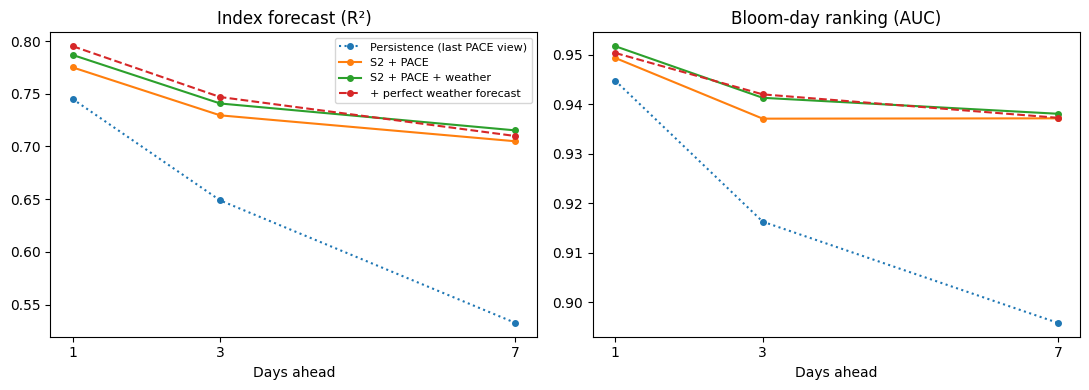

In [42]:
# ------------------------------------------------------------------
# Skill against lead time
# ------------------------------------------------------------------
# Left: how well the index value is forecast. Right: how well bloom days are ranked.
# Dotted = persistence baseline; solid = usable models; dashed = upper limit with perfect weather.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
styles = {"Persistence (last PACE view)": ":", "S2 + PACE": "-", "S2 + PACE + weather": "-", "+ perfect weather forecast": "--"}
for ax, results, metric, title in [
    (axes[0], index_results_df, "R²", "Index forecast (R²)"),
    (axes[1], risk_results_df, "AUC", "Bloom-day ranking (AUC)"),
]:
    by_lead = results[metric].unstack("model")   # rows = lead times, columns = models
    for name in model_order:
        ax.plot(by_lead.index, by_lead[name], styles[name], marker="o", ms=4, label=name)
    ax.set_xticks(RISK_LEADS)
    ax.set_xlabel("Days ahead")
    ax.set_title(title)
axes[0].legend(fontsize=8)   # one legend is enough
plt.tight_layout()
plt.show()

### Final risk models and the outlook table

One risk model per lead time, refitted on all rows and saved. For each lead time it uses whichever usable input set had the higher cross-validated AUC (with or without weather).

The outlook table then shows what a warning would look like: the bloom risk at every point 1, 3 and 7 days after the **issue day**, the latest day with both PACE and weather data. A point shows "No recent clear view" when either satellite has no clear view inside its lookback window, because the models were only trained on rows that had both.

1-day risk model: 'S2 + PACE + weather' (1,467 rows) saved to bloom_risk_lead1.txt
3-day risk model: 'S2 + PACE + weather' (1,467 rows) saved to bloom_risk_lead3.txt
7-day risk model: 'S2 + PACE + weather' (1,467 rows) saved to bloom_risk_lead7.txt

Bloom risk outlook, issued 2026-09-01:


,Sep 02 (+1d),Sep 04 (+3d),Sep 08 (+7d)
point_id,,,
Lake Erie #1,High (99%),High (99%),High (98%)
Lake Erie #2,Low (1%),Low (1%),Low (0%)
Lake Erie #3,High (96%),High (96%),High (95%)
Lake Erie #4,High (99%),High (98%),High (96%)
Lake Erie #5,No recent clear view,No recent clear view,No recent clear view
Lake Erie #6,High (97%),High (94%),High (67%)
Lake Erie #7,Low (25%),High (75%),Moderate (47%)
Lake Erie #8,High (79%),High (75%),Moderate (52%)
Saginaw Bay #1,Low (7%),Low (7%),Low (1%)


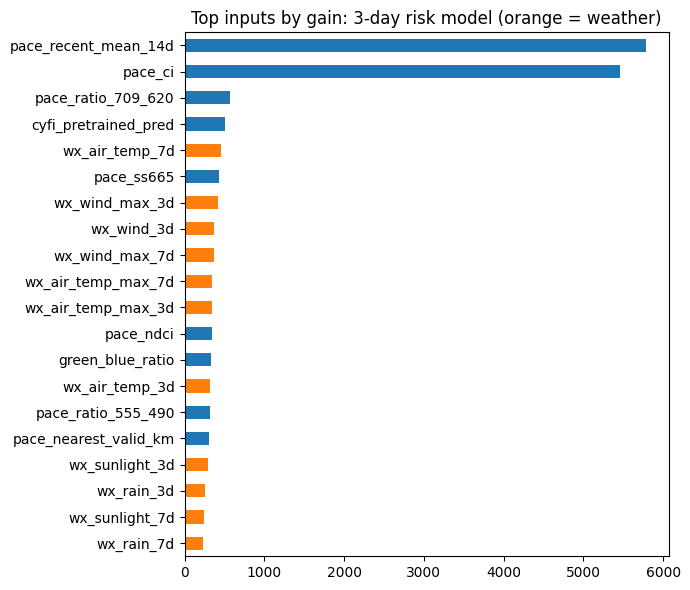

In [43]:
# ------------------------------------------------------------------
# Train the final risk models, save them, and print the outlook
# ------------------------------------------------------------------
import json

final_risk_models, final_risk_sets = {}, {}
for lead, table in lead_tables.items():
    # Higher cross-validated AUC among the usable sets
    best = risk_results_df.loc[lead].loc[USABLE_SETS, "AUC"].idxmax()
    final_risk_sets[lead] = best
    # Cross-validation was only for scoring; the final model learns from every row
    final_risk_models[lead] = lgb.LGBMClassifier(**LGB_PARAMS).fit(table[RISK_FEATURE_SETS[best]], risk_bloom)
    final_risk_models[lead].booster_.save_model(f"bloom_risk_lead{lead}.txt")   # reload with lgb.Booster(model_file=...)
    print(f"{lead}-day risk model: '{best}' ({len(table):,} rows) saved to bloom_risk_lead{lead}.txt")

# Save the settings needed to reuse the models correctly
with open("bloom_risk_meta.json", "w") as f:
    json.dump(
        {
            "target": f"bloom day = {TARGET_INDEX} above bloom_threshold",
            "bloom_threshold": float(BLOOM_THRESHOLD),
            "warn_at": WARN_AT,
            "risk_levels": RISK_LEVELS,
            "pace_lookback_days": PACE_LOOKBACK_DAYS,
            "s2_lookback_days": S2_LOOKBACK_DAYS,
            "weather_windows_days": WEATHER_WINDOWS,
            "weather_source": "NASA POWER daily point API",
            "models": {str(lead): {"file": f"bloom_risk_lead{lead}.txt", "feature_set": final_risk_sets[lead],
                                   "features": RISK_FEATURE_SETS[final_risk_sets[lead]]} for lead in RISK_LEADS},
            "lakes": LAKES,
            "seasons": SEASONS,
            "n_train": int(len(risk_y)),
        },
        f,
        indent=2,
    )

# --- Outlook: the risk at every point after the latest day with data ---
ISSUE_DAY = min(pace_obs["date"].max(), weather["date"].max())   # the day the forecast is made
outlook = points[["point_id"]].copy()
for lead in RISK_LEADS:
    rows = points[["point_id", "lake"]].assign(date=ISSUE_DAY + pd.Timedelta(days=lead))   # the day being forecast
    table = build_lead_table(lead, rows, keep_all=True).set_index("point_id").loc[outlook["point_id"]]
    prob = final_risk_models[lead].predict_proba(table[RISK_FEATURE_SETS[final_risk_sets[lead]]])[:, 1]
    seen = (table["pace_date"].notna() & table["s2_date"].notna()).values   # both satellites saw it recently, as in training
    outlook[f"{ISSUE_DAY + pd.Timedelta(days=lead):%b %d} (+{lead}d)"] = [
        f"{level} ({p:.0%})" if ok else "No recent clear view"
        for level, p, ok in zip(risk_level(prob), prob, seen)
    ]
print(f"\nBloom risk outlook, issued {ISSUE_DAY:%Y-%m-%d}:")
display(outlook.set_index("point_id"))

# Feature importance by "gain" for the middle lead time: does the model lean on weather?
mid_lead = RISK_LEADS[len(RISK_LEADS) // 2]
mid_cols = RISK_FEATURE_SETS[final_risk_sets[mid_lead]]
risk_importance = pd.Series(final_risk_models[mid_lead].booster_.feature_importance("gain"), index=mid_cols).sort_values()
colours = ["tab:orange" if c.startswith("wx") else "tab:blue" for c in risk_importance.tail(20).index]   # orange = weather
risk_importance.tail(20).plot(kind="barh", figsize=(7, 6), color=colours,
                              title=f"Top inputs by gain: {mid_lead}-day risk model (orange = weather)")
plt.tight_layout()
plt.show()

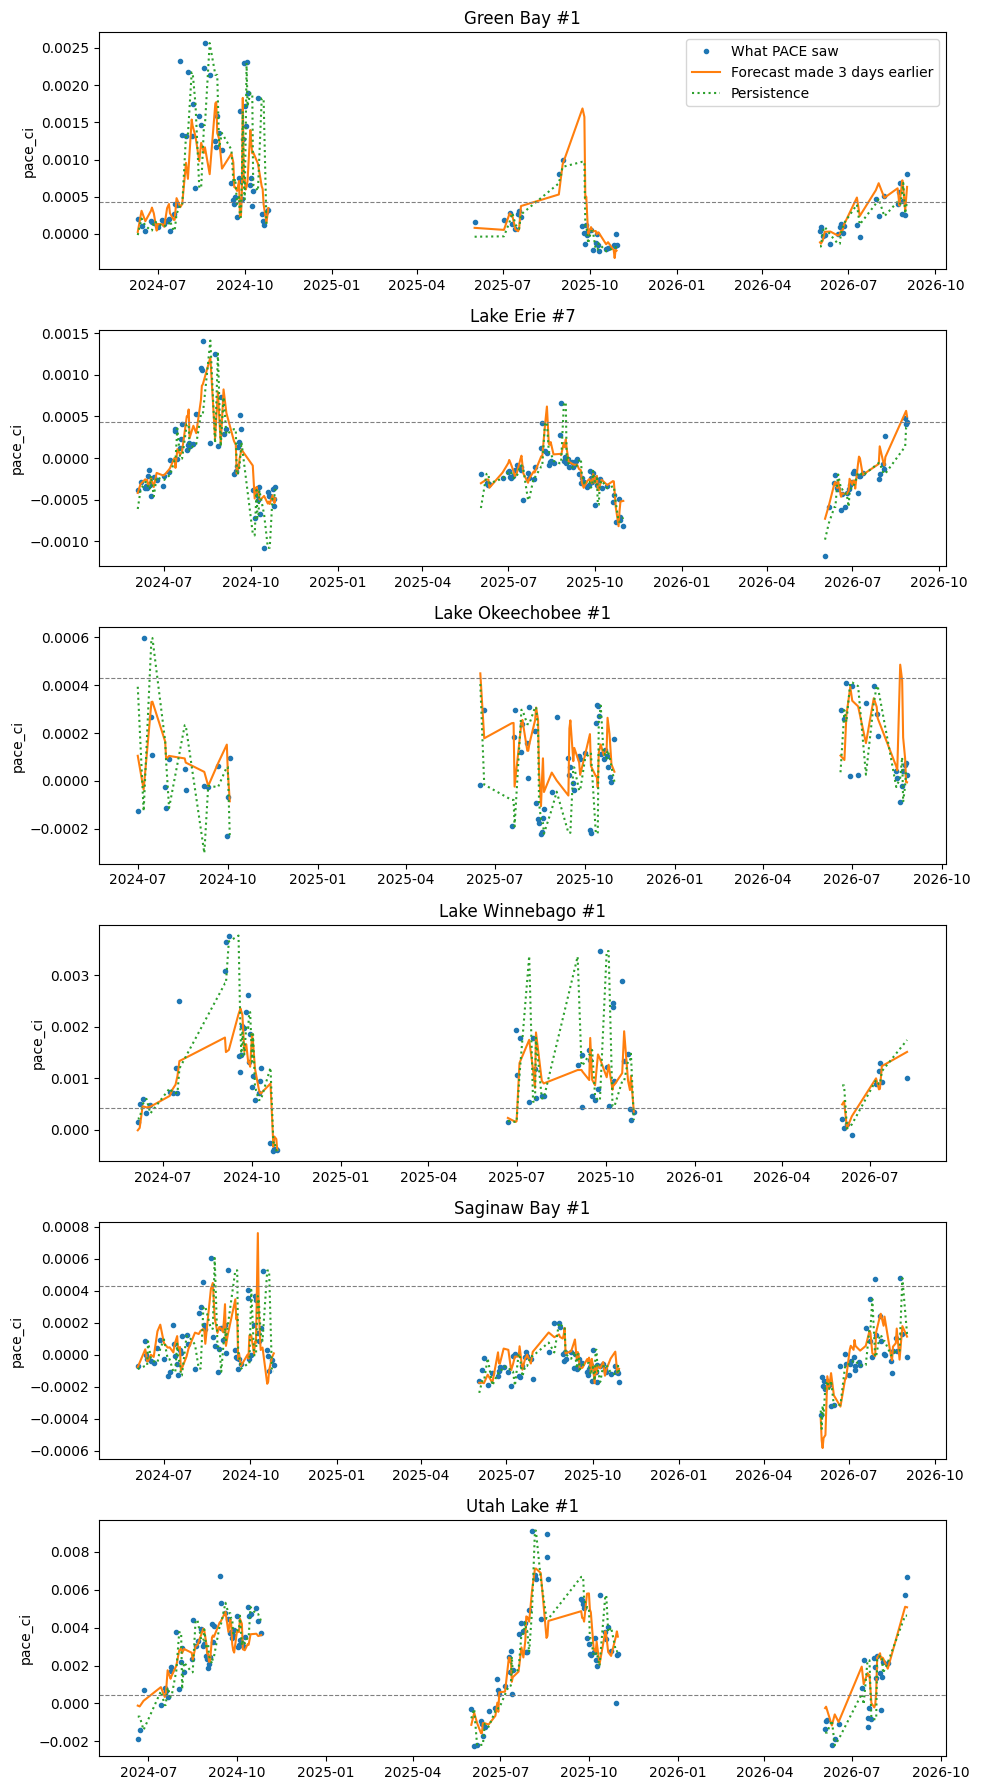

In [45]:
# ------------------------------------------------------------------
# Forecast vs. what PACE saw, with weather: the busiest point in each lake
# ------------------------------------------------------------------
plot_lead = 3                        # which lead time to show: 1, 3 or 7
plot_model = "S2 + PACE + weather"   # which model to show
table = lead_tables[plot_lead]
pred = index_oof[(plot_lead, plot_model)]   # each forecast came from a model that never saw that week

lake_points = table.groupby("lake")["point_id"].agg(lambda s: s.value_counts().idxmax())   # busiest point per lake
fig, axes = plt.subplots(len(lake_points), 1, figsize=(10, 3 * len(lake_points)), squeeze=False)   # one panel per lake

for ax, (lake, point) in zip(axes[:, 0], lake_points.items()):
    rows = table[table["point_id"] == point]
    for i, (year, season) in enumerate(rows.groupby(rows["date"].dt.year)):   # one season at a time, so winters aren't joined up
        first = i == 0   # label only the first season, so the legend has one entry each
        ax.plot(season["date"], season["target"], "o", ms=3, color="tab:blue", label="What PACE saw" if first else None)
        ax.plot(season["date"], pred[season.index], "-", color="tab:orange", label=f"Forecast made {plot_lead} days earlier" if first else None)
        ax.plot(season["date"], season[TARGET_INDEX], ":", color="tab:green", label="Persistence" if first else None)
    ax.axhline(BLOOM_THRESHOLD, color="grey", lw=0.8, ls="--")   # bloom threshold
    ax.set_title(point)
    ax.set_ylabel(TARGET_INDEX)

axes[0, 0].legend()   # one legend is enough
plt.tight_layout()    # stop panels overlapping
plt.show()